# 05 - Stage 3 (Boosting): XGBoost

**Boosting** builds trees *in sequence*. Each new, shallow tree is fitted to
the errors the ensemble has made so far, so the model concentrates on the
epochs it currently gets wrong. Where bagging reduces variance by averaging
independent trees, boosting reduces bias by stacking corrections.

XGBoost is the standard implementation: gradient boosting with built-in
regularisation, column subsampling, and early stopping. It is usually the
strongest classical model on tabular data - which makes its result on 121
subjects informative either way.

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

CACHE = "data/epochs.npz"
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

## Step 1 - Load the preprocessed epochs

**What this does.** Loads the cache written by notebook `01`: every 2-second EEG
window ("epoch"), its 456 hand-engineered features, the label, and - crucially -
the ID of the subject it came from.

**Why the subject ID matters.** Each person contributes many epochs (61 to 336
of them). If epochs from the same person landed in both training and test sets,
the model could score well by recognising the *person* rather than ADHD - the
label is constant within a subject, so recognising the subject gives the label
away. The subject ID is what lets us prevent that in Step 2.

In [2]:
if not os.path.exists(CACHE):
    raise FileNotFoundError("Run 01_Data_and_Preprocessing.ipynb first - it builds " + CACHE)

cache = np.load(CACHE, allow_pickle=True)
X_feat, y, groups = cache["Xf"], cache["y"].astype(int), cache["g"]

# Band powers span several orders of magnitude and are right-skewed; log1p
# compresses that range so no single feature dominates distance-based or
# gradient-based models. Trees are unaffected either way.
X = np.log1p(np.clip(X_feat, 0, None))
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

subj = pd.DataFrame({"ID": groups, "y": y}).groupby("ID").y.first()
print("epochs   :", X.shape[0])
print("features :", X.shape[1])
print("subjects :", len(subj), "  (%d ADHD, %d Control)" % (subj.sum(), (1 - subj).sum()))

epochs   : 16749
features : 456
subjects : 121   (61 ADHD, 60 Control)


## Step 2 - Build subject-grouped cross-validation folds

**What this does.** Splits the 121 subjects into 5 folds. Each fold holds out
about 24 *people*; all of their epochs go to the test side together.
`StratifiedGroupKFold` keeps the ADHD/Control balance similar across folds.

**Why 5 folds and not one split.** With only 121 subjects, which particular
people end up in the test set changes the score a lot. Five folds give five
estimates, and we report their mean and spread. A single split would hide that
spread entirely.

**Why there is an `assert`.** It is cheap insurance: if a future change ever
lets a subject leak across a split, the notebook stops here instead of quietly
reporting an inflated number.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, SEED = 5, 42
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
          .split(X, y, groups))

for k, (tr, te) in enumerate(cv):
    assert not (set(groups[tr]) & set(groups[te])), "subject leaked across split!"
    print("fold %d: train %5d epochs / %2d subjects   test %4d epochs / %2d subjects"
          % (k, len(tr), len(set(groups[tr])), len(te), len(set(groups[te]))))
print("\nVerified: no subject appears on both sides of any fold.")

fold 0: train 13419 epochs / 97 subjects   test 3330 epochs / 24 subjects
fold 1: train 13412 epochs / 97 subjects   test 3337 epochs / 24 subjects
fold 2: train 13342 epochs / 96 subjects   test 3407 epochs / 25 subjects
fold 3: train 13413 epochs / 97 subjects   test 3336 epochs / 24 subjects
fold 4: train 13410 epochs / 97 subjects   test 3339 epochs / 24 subjects

Verified: no subject appears on both sides of any fold.


## Step 3 - Define how a model is scored

**What this does.** Two helpers used by every model notebook.

- `subject_scores` turns epoch-level predictions into one decision per person
  by **averaging that person's epoch probabilities**, then scores those
  decisions. This is the number that matters: diagnosis happens per person, not
  per 2-second window.
- `save_result` writes the 5-fold summary (and each fold's score) to
  `results.csv` / `results_folds.csv`, which notebook `07` reads.

**Why ROC-AUC alongside accuracy.** Accuracy depends on where the 0.5 cut-off
sits; ROC-AUC measures how well the model *ranks* ADHD subjects above controls,
regardless of the cut-off. Both are reported. The standard deviation is the
sample SD across the 5 folds.

In [4]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve

def subject_scores(g_te, y_te, p):
    """Average epoch probabilities per subject, then score the per-subject decision."""
    s = (pd.DataFrame({"ID": g_te, "y": y_te, "p": p})
         .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    pred = (s.p > 0.5).astype(int)
    return roc_auc_score(s.y, s.p), accuracy_score(s.y, pred), f1_score(s.y, pred)

def save_result(model, stage, res, path="results.csv"):
    """Upsert one model's summary row; per-fold rows go to results_folds.csv."""
    row = dict(model=model, stage=stage, n_folds=len(res))
    for c in ("epoch_auc", "subject_auc", "subject_acc", "subject_f1"):
        row[c], row[c + "_sd"] = res[c].mean(), res[c].std()
    for p, new in ((path, pd.DataFrame([row])),
                   (path.replace(".csv", "_folds.csv"), res.assign(model=model, stage=stage))):
        try:
            old = pd.read_csv(p); old = old[old.model != model]
            new = pd.concat([old, new], ignore_index=True)
        except FileNotFoundError:
            pass
        new.sort_values(["stage", "model"]).to_csv(p, index=False)
    print("saved %s -> %s" % (model, path))

print("helpers defined")

helpers defined


## Step 4 - Define the model and its training procedure

**What this does.** Three configurations - one close to XGBoost's defaults
and two deliberately different ones - trained with early stopping.

**Why an inner validation split.** Early stopping needs a set to watch. If
that set were the test fold, the test fold would be choosing the number of
trees - a leak. So 20% of the *training subjects* (grouped, like everything
else) are held out as the watch set, and the test fold is touched only once.

**Why `scale_pos_weight`.** Same purpose as `class_weight="balanced"` earlier:
counteract the 56/44 epoch imbalance. Note that it shifts predicted
probabilities, which matters for the 0.5 cut-off - Step 8 returns to this.

**Why the reported configuration is fixed in advance.** Picking whichever of
the three scores best on the test folds would, again, let the test folds choose
the model. The reported one is the default-like configuration; the other two
serve as a sensitivity check.

In [5]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit

CONFIGS = {
    "default-like": dict(n_estimators=400, max_depth=6, learning_rate=0.10, subsample=0.9, colsample_bytree=0.9),
    "regularised":  dict(n_estimators=700, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.5,
                         min_child_weight=5, reg_lambda=2.0, reg_alpha=0.5),
    "deep":         dict(n_estimators=500, max_depth=9, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7,
                         min_child_weight=3, reg_lambda=1.0),
}
REPORTED = "default-like"

def fit_xgb(cfg, tr, early_stopping=True):
    pos, neg = (y[tr] == 1).sum(), (y[tr] == 0).sum()
    m = XGBClassifier(**CONFIGS[cfg], tree_method="hist", eval_metric="auc", scale_pos_weight=neg / pos,
                      random_state=42, n_jobs=-1, early_stopping_rounds=50 if early_stopping else None)
    if not early_stopping:
        return m.fit(X[tr], y[tr], verbose=False)
    itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42).split(X[tr], y[tr], groups[tr]))
    return m.fit(X[tr][itr], y[tr][itr], eval_set=[(X[tr][iva], y[tr][iva])], verbose=False)

print("reported configuration:", REPORTED, CONFIGS[REPORTED])

reported configuration: default-like {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.1, 'subsample': 0.9, 'colsample_bytree': 0.9}


## Step 5 - Train and evaluate across the 5 folds

**What this does.** Runs all three configurations through the same folds.
`best_iter` is the number of trees early stopping settled on - a small number
means validation AUC peaked quickly and the model began overfitting after only
a few dozen trees.

In [6]:
results, oof = {}, {}
t0 = time.time()
for cfg in CONFIGS:
    rows, P, Y, G = [], [], [], []
    for k, (tr, te) in enumerate(cv):
        m = fit_xgb(cfg, tr)
        p = m.predict_proba(X[te])[:, 1]
        s_auc, s_acc, s_f1 = subject_scores(groups[te], y[te], p)
        rows.append(dict(fold=k, epoch_auc=roc_auc_score(y[te], p), subject_auc=s_auc,
                         subject_acc=s_acc, subject_f1=s_f1, best_iter=m.best_iteration))
        P.append(p); Y.append(y[te]); G.append(groups[te])
        print("  %-12s fold %d  epoch-AUC %.3f | subject-AUC %.3f  subject-acc %.3f | trees %d"
              % (cfg, k, rows[-1]["epoch_auc"], s_auc, s_acc, m.best_iteration))
    results[cfg] = pd.DataFrame(rows); oof[cfg] = tuple(map(np.concatenate, (P, Y, G)))
print("done in %.0f s" % (time.time() - t0))

res = results[REPORTED]
oof_p, oof_y, oof_g = oof[REPORTED]
print("\nXGBoost (%s)  -  5-fold results" % REPORTED)
for c in ["epoch_auc", "subject_auc", "subject_acc", "subject_f1"]:
    print("  %-12s %.3f +- %.3f" % (c, res[c].mean(), res[c].std()))
save_result("XGBoost", "3 - Boosting", res)

  default-like fold 0  epoch-AUC 0.738 | subject-AUC 0.861  subject-acc 0.708 | trees 399


  default-like fold 1  epoch-AUC 0.751 | subject-AUC 0.854  subject-acc 0.792 | trees 191


  default-like fold 2  epoch-AUC 0.777 | subject-AUC 0.872  subject-acc 0.800 | trees 75


  default-like fold 3  epoch-AUC 0.707 | subject-AUC 0.701  subject-acc 0.667 | trees 33


  default-like fold 4  epoch-AUC 0.678 | subject-AUC 0.681  subject-acc 0.625 | trees 161


...

  deep         fold 0  epoch-AUC 0.693 | subject-AUC 0.833  subject-acc 0.583 | trees 8


  deep         fold 1  epoch-AUC 0.699 | subject-AUC 0.833  subject-acc 0.500 | trees 0


  deep         fold 2  epoch-AUC 0.785 | subject-AUC 0.878  subject-acc 0.840 | trees 122


  deep         fold 3  epoch-AUC 0.711 | subject-AUC 0.694  subject-acc 0.667 | trees 79


  deep         fold 4  epoch-AUC 0.676 | subject-AUC 0.674  subject-acc 0.667 | trees 119
done in 213 s

XGBoost (default-like)  -  5-fold results
  epoch_auc    0.730 +- 0.039
  subject_auc  0.794 +- 0.094
  subject_acc  0.718 +- 0.077
  subject_f1   0.760 +- 0.045
saved XGBoost -> results.csv


## Step 6 - Sensitivity: did the configuration matter?

**What this does.** Puts the three configurations side by side.

**How to read it.** If the spread *between* configurations is smaller than the
spread *between folds* of any one of them, the choice of hyperparameters is
inside the noise - the result does not hinge on it.

In [7]:
summary = pd.DataFrame({
    cfg: dict(subject_auc=r.subject_auc.mean(), subject_auc_sd=r.subject_auc.std(),
              subject_acc=r.subject_acc.mean(), epoch_auc=r.epoch_auc.mean(),
              median_trees=r.best_iter.median())
    for cfg, r in results.items()}).T
display(summary.round(3))

spread, noise = summary.subject_auc.max() - summary.subject_auc.min(), summary.subject_auc_sd.max()
print("spread between configurations : %.3f" % spread)
print("largest fold-to-fold SD        : %.3f" % noise)
print("-> configuration choice is %s the noise." % ("inside" if spread < noise else "larger than"))

,subject_auc,subject_auc_sd,subject_acc,epoch_auc,median_trees
default-like,0.794,0.094,0.718,0.730,161.0
regularised,0.770,0.092,0.677,0.721,79.0
deep,0.783,0.092,0.651,0.713,79.0


spread between configurations : 0.024
largest fold-to-fold SD        : 0.094
-> configuration choice is inside the noise.


## Step 7 - One decision per subject

**What this does.** Pools the out-of-fold predictions - every subject was in a
test fold exactly once - and makes the final per-person call by averaging that
person's epoch probabilities.

**Why the pooled numbers differ slightly from the fold means.** The fold means
average five scores each computed on about 24 people; the pooled score is
computed once on all 121. Both are legitimate; the fold mean comes with a
spread, which is why the tables quote it.

In [8]:
subject_pred = (pd.DataFrame({"ID": oof_g, "y_true": oof_y, "p": oof_p})
                .groupby("ID").agg(y_true=("y_true", "first"), p_adhd=("p", "mean")))
subject_pred["pred"] = (subject_pred.p_adhd > 0.5).astype(int)
subject_pred["correct"] = subject_pred.pred == subject_pred.y_true

print("Pooled subject-level performance (n = %d)" % len(subject_pred))
print("  accuracy : %.3f" % accuracy_score(subject_pred.y_true, subject_pred.pred))
print("  ROC-AUC  : %.3f" % roc_auc_score(subject_pred.y_true, subject_pred.p_adhd))
print("  F1       : %.3f" % f1_score(subject_pred.y_true, subject_pred.pred))

wrong = subject_pred[~subject_pred.correct].assign(margin=lambda d: (d.p_adhd - .5).abs())
print("\n%d of %d subjects misclassified. Most confident mistakes:" % (len(wrong), len(subject_pred)))
display(wrong.sort_values("margin", ascending=False).head(5).round(3))

Pooled subject-level performance (n = 121)
  accuracy : 0.719
  ROC-AUC  : 0.786
  F1       : 0.757

34 of 121 subjects misclassified. Most confident mistakes:


,y_true,p_adhd,pred,correct,margin
ID,,,,,
v140,0,0.913,1,False,0.413
v27p,1,0.090,0,False,0.410
v51p,0,0.898,1,False,0.398
v45p,0,0.858,1,False,0.358
v49p,0,0.847,1,False,0.347


## Step 8 - The decision threshold

**What this does.** Compares subject accuracy at the default 0.5 cut-off with
a cut-off chosen on inner-validation subjects (never on the test fold).

**Why this step exists.** `scale_pos_weight` shifts probabilities, so 0.5 is
not necessarily where the model's "coin flip" sits. ROC-AUC is unaffected -
it only cares about ranking - but accuracy and F1 move with the cut-off. If
accuracy looks low next to the AUC, this is usually why.

In [9]:
def tuned_threshold(tr):
    """Pick the cut-off that maximises subject-level F1 on an inner validation split."""
    itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=.25, random_state=7).split(X[tr], y[tr], groups[tr]))
    pos, neg = (y[tr][itr] == 1).sum(), (y[tr][itr] == 0).sum()
    m = XGBClassifier(**CONFIGS[REPORTED], tree_method="hist", scale_pos_weight=neg / pos,
                      random_state=42, n_jobs=-1).fit(X[tr][itr], y[tr][itr], verbose=False)
    sv = (pd.DataFrame({"ID": groups[tr][iva], "y": y[tr][iva], "p": m.predict_proba(X[tr][iva])[:, 1]})
          .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    grid = np.linspace(.05, .95, 91)
    return grid[int(np.argmax([f1_score(sv.y, (sv.p > t).astype(int)) for t in grid]))]

acc05, acc_t, thr = [], [], []
for k, (tr, te) in enumerate(cv):
    s = subject_pred.loc[subject_pred.index.isin(np.unique(groups[te]))]
    t = tuned_threshold(tr); thr.append(t)
    acc05.append(accuracy_score(s.y_true, (s.p_adhd > .5).astype(int)))
    acc_t.append(accuracy_score(s.y_true, (s.p_adhd > t).astype(int)))

print("tuned thresholds per fold :", np.round(thr, 2))
print("subject accuracy @ 0.5    : %.3f +- %.3f" % (np.mean(acc05), np.std(acc05, ddof=1)))
print("subject accuracy @ tuned  : %.3f +- %.3f" % (np.mean(acc_t), np.std(acc_t, ddof=1)))
print("(ROC-AUC is unchanged by this; only the accuracy/F1 cut-off moves)")

tuned thresholds per fold : [0.24 0.4  0.64 0.07 0.56]
subject accuracy @ 0.5    : 0.718 +- 0.077
subject accuracy @ tuned  : 0.652 +- 0.099
(ROC-AUC is unchanged by this; only the accuracy/F1 cut-off moves)


## Step 9 - Confusion matrix and ROC curve

**How to read them.** Left column: every 2-second epoch scored on its own.
Right column: one decision per subject. The subject-level matrix has 121 cells
in total - the top-right cell is controls flagged as ADHD, the bottom-left is
ADHD subjects missed. The ROC curve plots sensitivity against false-alarm rate
at every possible cut-off; the area under it is the ROC-AUC quoted above.

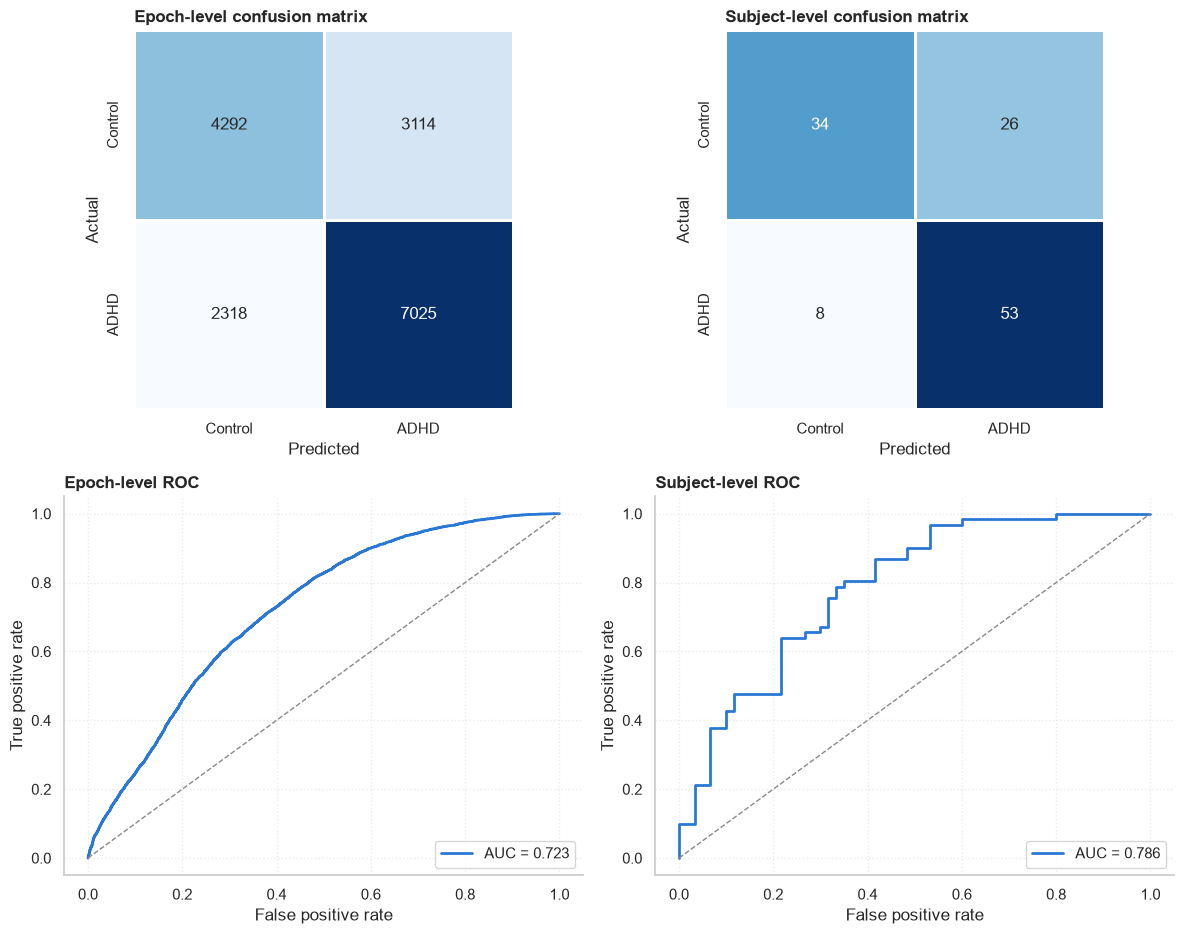

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
levels = [(oof_y, oof_p, "Epoch"),
          (subject_pred.y_true.values, subject_pred.p_adhd.values, "Subject")]

for col, (yy, pp, lvl) in enumerate(levels):
    cm = confusion_matrix(yy, (pp > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1, linecolor="white", ax=ax[0, col],
                xticklabels=["Control", "ADHD"], yticklabels=["Control", "ADHD"])
    ax[0, col].set_title("%s-level confusion matrix" % lvl, weight="bold", loc="left")
    ax[0, col].set_xlabel("Predicted"); ax[0, col].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(yy, pp)
    ax[1, col].plot(fpr, tpr, lw=2, color=BLUE, label="AUC = %.3f" % roc_auc_score(yy, pp))
    ax[1, col].plot([0, 1], [0, 1], "--", color="#8a8a85", lw=1)
    ax[1, col].set_title("%s-level ROC" % lvl, weight="bold", loc="left")
    ax[1, col].set_xlabel("False positive rate"); ax[1, col].set_ylabel("True positive rate")
    ax[1, col].legend(loc="lower right"); ax[1, col].grid(alpha=.4, ls=":")
    for sp in ("top", "right"): ax[1, col].spines[sp].set_visible(False)

plt.tight_layout(); plt.show()

## Step 10 - Which features did the booster use?

**What this does.** Gain-based importance (how much each feature improved the
loss when used in a split), averaged over five full-data fold models, shown by
feature and summed by family. Same caution as before about correlated features
sharing credit.

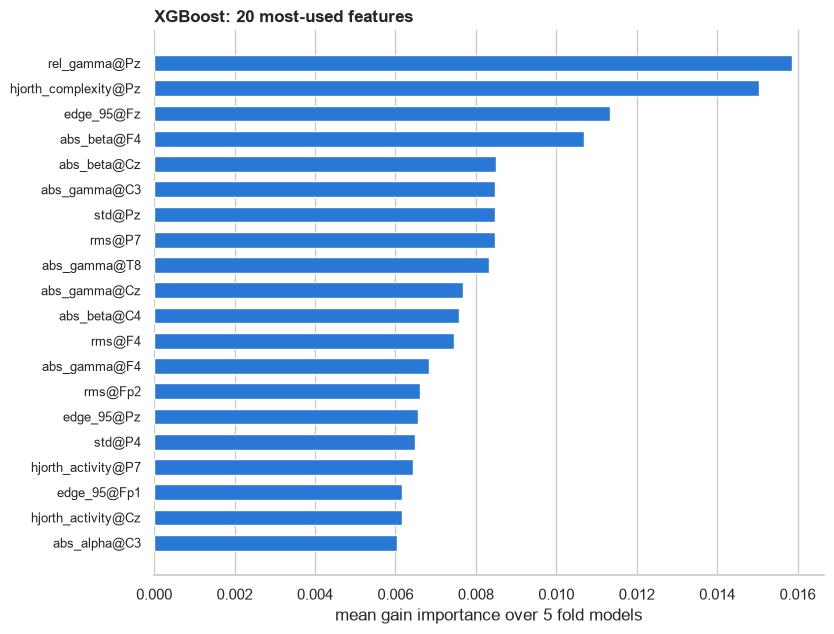

Gain by feature family:
abs_gamma            0.080
abs_beta             0.077
rms                  0.070
hjorth_activity      0.065
hjorth_complexity    0.065
std                  0.064
edge_95              0.061
rel_gamma            0.058
hjorth_mobility      0.048
abs_alpha            0.045


In [11]:
names = cache["feature_names"]
gain = np.zeros(X.shape[1])
for tr, te in cv:
    gain += fit_xgb(REPORTED, tr, early_stopping=False).feature_importances_
gain = pd.Series(gain / len(cv), index=names)
top = gain.sort_values(ascending=False)[:20]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(range(len(top))[::-1], top.values, height=.62, color=BLUE)
ax.set_yticks(range(len(top))[::-1], top.index, fontsize=9)
ax.set_xlabel("mean gain importance over 5 fold models")
ax.set_title("XGBoost: 20 most-used features", weight="bold", loc="left")
ax.grid(axis="y", visible=False)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

fam = gain.groupby([n.split("@")[0] for n in names]).sum().sort_values(ascending=False)
print("Gain by feature family:"); print(fam.head(10).round(3).to_string())

## Step 11 - How much the score moves from fold to fold

**Why this plot is here.** It is the honest picture of uncertainty. Each pair
of bars is one fold - one particular set of ~24 test subjects. The gap between
the best and worst fold is what a single train/test split would have hidden:
the same model, the same code, and a score that depends on which people were
held out.

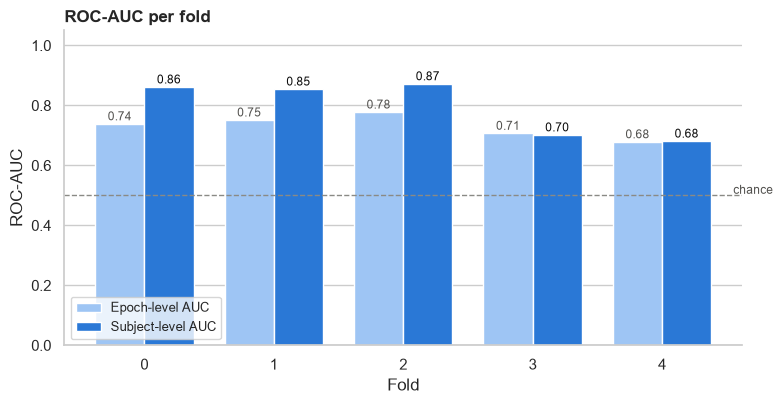

subject-AUC: best fold 0.872, worst fold 0.681, spread 0.191


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38
ax.bar(res.fold - w/2, res.epoch_auc, w, color="#9ec5f4", label="Epoch-level AUC")
ax.bar(res.fold + w/2, res.subject_auc, w, color=BLUE, label="Subject-level AUC")
for f, e, s in zip(res.fold, res.epoch_auc, res.subject_auc):
    ax.text(f - w/2, e + .012, "%.2f" % e, ha="center", fontsize=8.5, color=MUTED)
    ax.text(f + w/2, s + .012, "%.2f" % s, ha="center", fontsize=8.5, color=INK)
ax.axhline(.5, ls="--", lw=1, color="#8a8a85"); ax.text(4.55, .505, "chance", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.05); ax.set_xticks(res.fold); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold", weight="bold", loc="left")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("subject-AUC: best fold %.3f, worst fold %.3f, spread %.3f"
      % (res.subject_auc.max(), res.subject_auc.min(), res.subject_auc.max() - res.subject_auc.min()))

## How to report this

- Quote the **subject-level** figures **with their +- SD**. With ~24 subjects
  per test fold, one person is worth about 4 percentage points of accuracy, so
  the spread is part of the result.
- Compare against the other stages in `07_Model_Comparison.ipynb`. A model
  whose mean is higher by less than one standard deviation has **not** been
  shown to be better on this data.
- **On boosting specifically:** the per-person decision rests on ~97 training
  subjects per fold, however many epochs they contributed. Boosting's capacity
  is far larger than that supports, and small `best_iter` values are the
  symptom. "The extra capacity bought nothing" is a result worth stating.